In [1]:
import os, sys
os.environ['CUDA_VISIBLE_DEVICES'] = "1"
import torch
import numpy as np
import pandas as pd
import umap
import random
from scipy.spatial import distance
import matplotlib.pyplot as plt
from matplotlib import colors
sys.path.append("../src")
from utils import *
os.chdir("../")

/export/raid1/home/kneel027/miniconda3/envs/SS/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:

subject = 1
# passes = 5
reps = 1
embed_dim = 197376
# model_name = f"mindeye_mcd_{passes}passes_0.15dr"
drs = [0.15, 0.4]#, 0.6, 0.8]
num_passes = [25] #1,5,10,

In [7]:
# Load CLIP block for NSD-Imagery
var_data = np.zeros((2, len(drs), len(num_passes)))
for i, dr in enumerate(drs):
    for j, passes in enumerate(num_passes):
        # mode x samples x reps x mcd passes x embedding size
        clip_block = torch.zeros((2,18,reps,passes,embed_dim))
        model_name = f"mindeye_mcd_{passes}passes_{dr}dr"
        for m, mode in enumerate(["imagery", "vision"]):
            path = f"output/mental_imagery_paper_b3/{mode}/{model_name}/subject{subject}/"
            for sample in range(18):
                for rep in range(reps):
                    clip_block[m, sample, rep] = torch.load(f"{path}{sample}/contrastive_clip_hidden_block_{rep}.pt", map_location="cpu")#.reshape((reps,257,768))
            
            repwise_var = torch.var(clip_block[m], axis=2)
            avg_var = torch.mean(repwise_var)
            var_data[m, i, j] = avg_var
            # print(clip_stats.shape)
            # print(clip_stats[0,0])
            # print(torch.mean(clip_stats[:,0], axis=0))
        var_diff = var_data[0, i, j] - var_data[1, i, j]
        print(f"{dr} DR, {passes} Passes, Var diff: ", var_diff)
        

/tmp/ipykernel_2001/1666627600.py:13: UserWarning: var(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at ../aten/src/ATen/native/ReduceOps.cpp:1760.)
  repwise_var = torch.var(clip_block[m], axis=2)


0.15 DR, 1 Passes, Var diff:  nan
0.15 DR, 5 Passes, Var diff:  0.053686901926994324
0.15 DR, 10 Passes, Var diff:  0.05276644229888916
0.15 DR, 25 Passes, Var diff:  0.05409078299999237
0.4 DR, 1 Passes, Var diff:  nan
0.4 DR, 5 Passes, Var diff:  0.04902936518192291
0.4 DR, 10 Passes, Var diff:  0.04973307251930237
0.4 DR, 25 Passes, Var diff:  0.05000971257686615
0.6 DR, 1 Passes, Var diff:  nan
0.6 DR, 5 Passes, Var diff:  0.052630022168159485
0.6 DR, 10 Passes, Var diff:  0.04945972561836243
0.6 DR, 25 Passes, Var diff:  0.05193941295146942
0.8 DR, 1 Passes, Var diff:  nan
0.8 DR, 5 Passes, Var diff:  0.04974789917469025
0.8 DR, 10 Passes, Var diff:  0.04868289828300476
0.8 DR, 25 Passes, Var diff:  0.04907597601413727


In [19]:
# Load CLIP block for shared1000
var_data = np.zeros((1, len(drs), len(num_passes)))
for i, dr in enumerate(drs):
    for j, passes in enumerate(num_passes):
        # mode x samples x reps x mcd passes x embedding size
        clip_block = torch.zeros((1,1000,reps,passes,embed_dim))
        model_name = f"mindeye_mcd_{passes}passes_{dr}dr_projector"
        path = f"output/{model_name}/subject{subject}/"
        # path = f"../output/mental_imagery_paper_b3/{mode}/{model_name}/subject{subject}/"
        for sample in range(1000):
            for rep in range(reps):
                clip_block[0,sample, rep] = torch.load(f"{path}{sample}/contrastive_clip_hidden_block_{rep}.pt", map_location="cpu")#.reshape((reps,257,768))
        
        repwise_var = torch.var(clip_block[0], axis=2)
        avg_var = torch.mean(repwise_var)
        # print(avg_var)
        print(f"{dr} DR, {passes} Passes, Var: ", avg_var)

0.15 DR, 25 Passes, Var:  tensor(0.2242)
0.4 DR, 25 Passes, Var:  tensor(0.6995)


In [12]:
from scipy.stats import pearsonr
import numpy as np
model = "mindeye_mcd_25passes_0.15dr"
mode = "vision"
print(f"Current Model: {model} in mode: {mode}")
df = pd.read_csv(f"../output/mental_imagery_paper_b3/{mode}/{model}/subject1_statistics_18.csv")
df = df[(df['Sample Indicator'] == 12)]# & (df['ID'] < 12)]
# print(df)
# df = df.replace([np.inf, -np.inf], np.nan)
non_image_metrics = ["CLIP Cosine", "Brain Correlation NSD General", "Brain Correlation Early Visual"]

for metric in non_image_metrics:
    filtered_df = df.dropna(subset=[metric]).replace([np.inf, -np.inf], np.nan)
    correlation, _ = pearsonr(filtered_df[metric], filtered_df['MCD Var'])
    print(f"{metric} Correlation-MCD Var Correlation: {correlation:.4f}")
    
df = df[(df['Sample Indicator'] == 12) & (df['ID'] < 12)]

image_metrics = ["SSIM", "Pixel Correlation", "AlexNet 2", "AlexNet 5", "AlexNet 7", "CLIP Two-way", "Inception V3"]
for metric in image_metrics:
    filtered_df = df.dropna(subset=[metric]).replace([np.inf, -np.inf], np.nan)
    correlation, _ = pearsonr(filtered_df[metric], filtered_df['MCD Var'])
    print(f"{metric}-MCD Var Correlation: {correlation:.4f}")

Current Model: mindeye_mcd_25passes_0.4dr_projector in mode: vision
CLIP Cosine Correlation-MCD Var Correlation: -0.2402
Brain Correlation NSD General Correlation-MCD Var Correlation: 0.2810
Brain Correlation Early Visual Correlation-MCD Var Correlation: 0.3317
SSIM-MCD Var Correlation: -0.2424
Pixel Correlation-MCD Var Correlation: 0.0030
AlexNet 2-MCD Var Correlation: 0.3992
AlexNet 5-MCD Var Correlation: 0.1393
AlexNet 7-MCD Var Correlation: 0.2556
CLIP Two-way-MCD Var Correlation: 0.3956
Inception V3-MCD Var Correlation: 0.3965


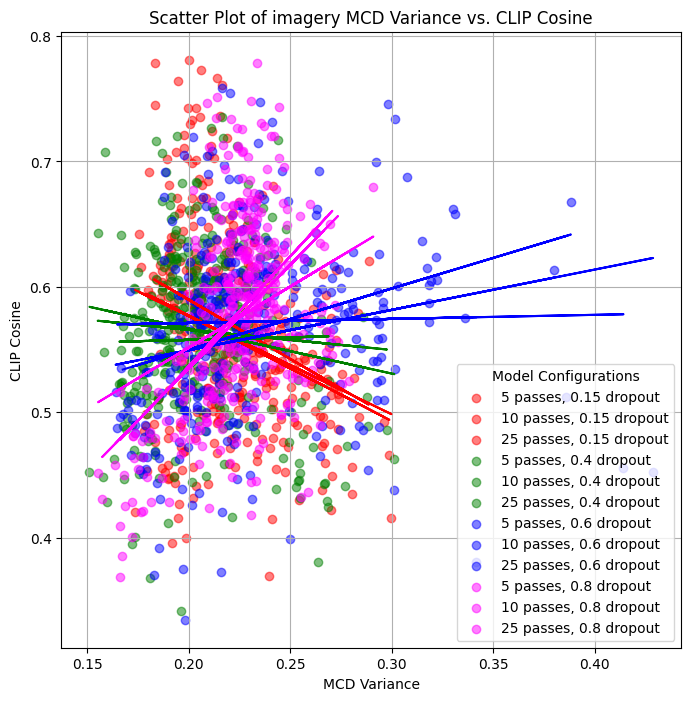

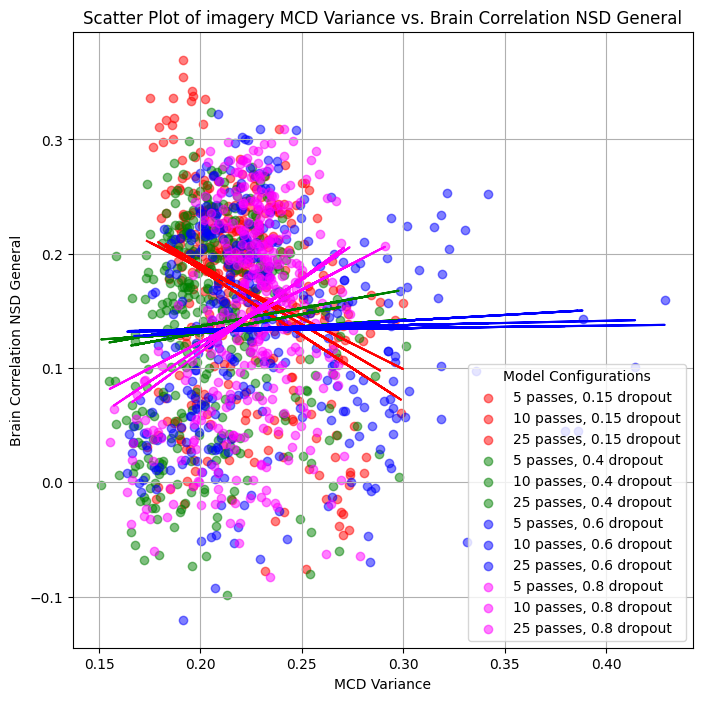

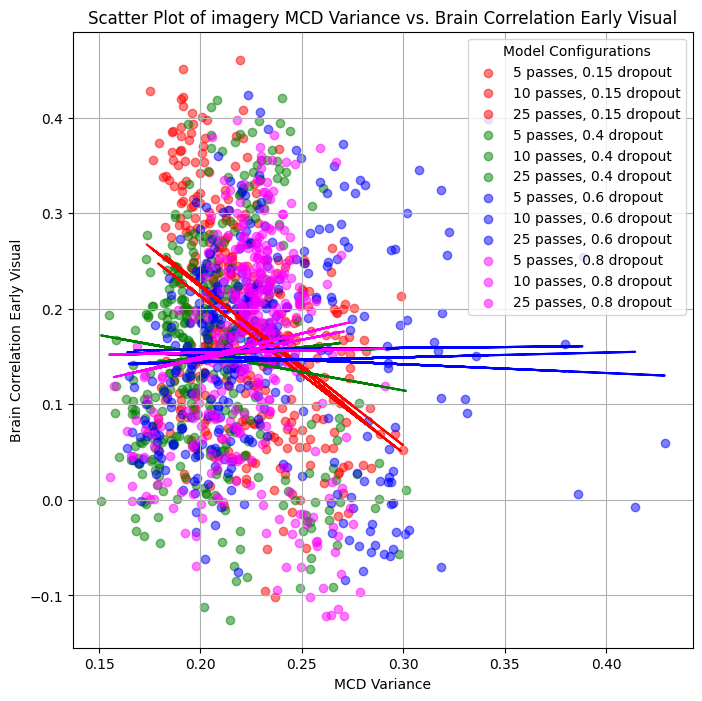

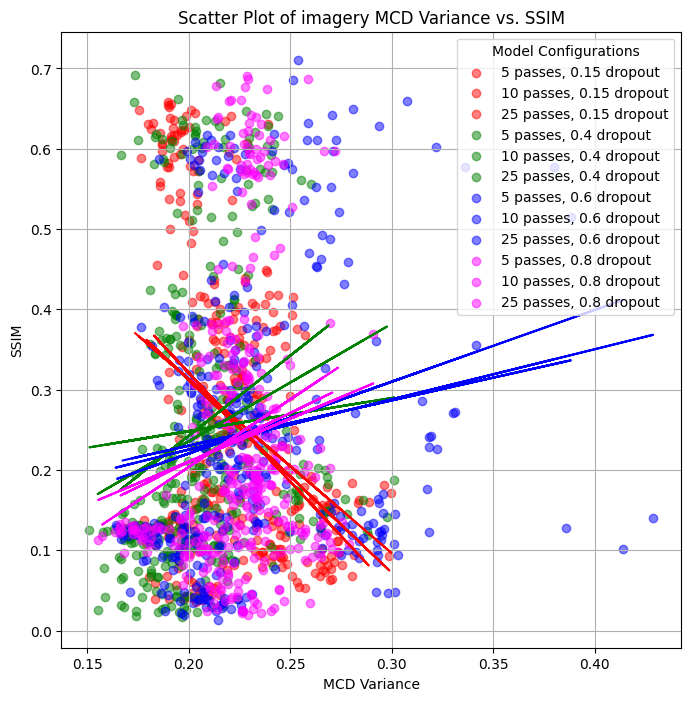

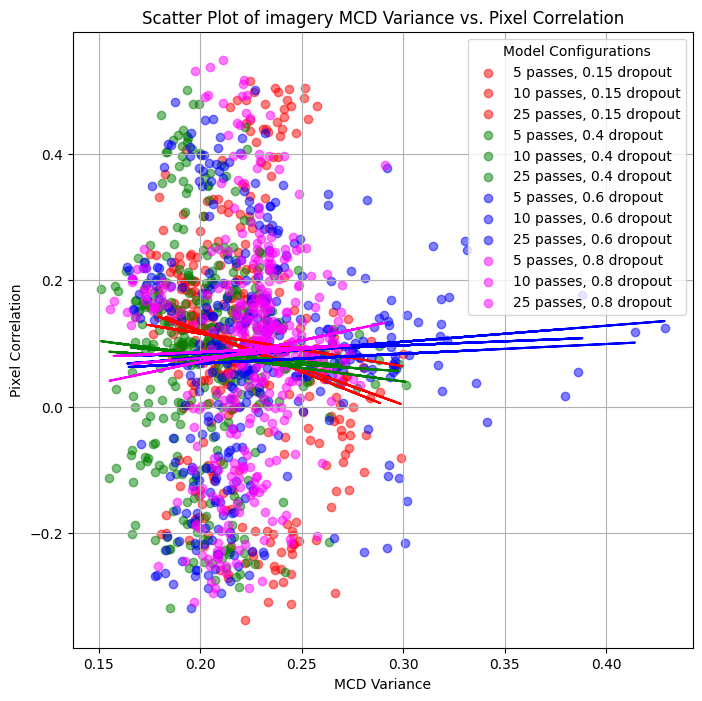

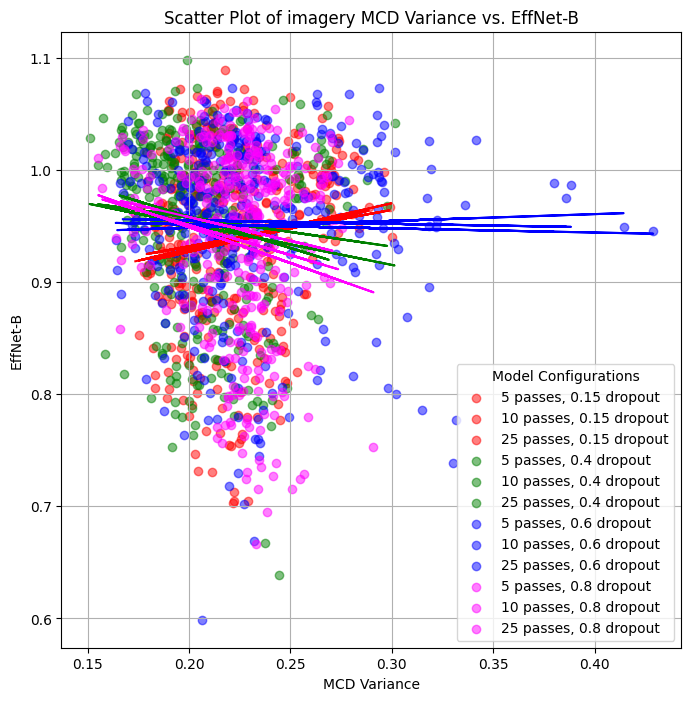

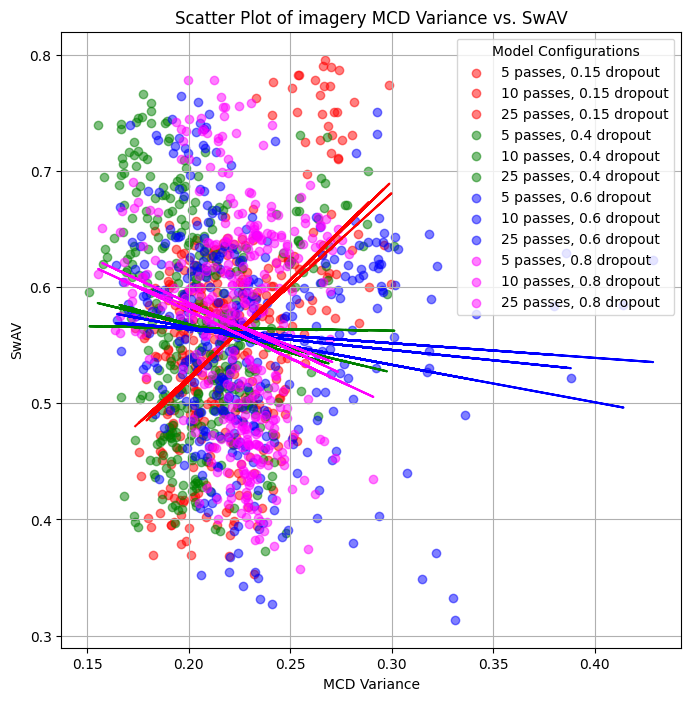

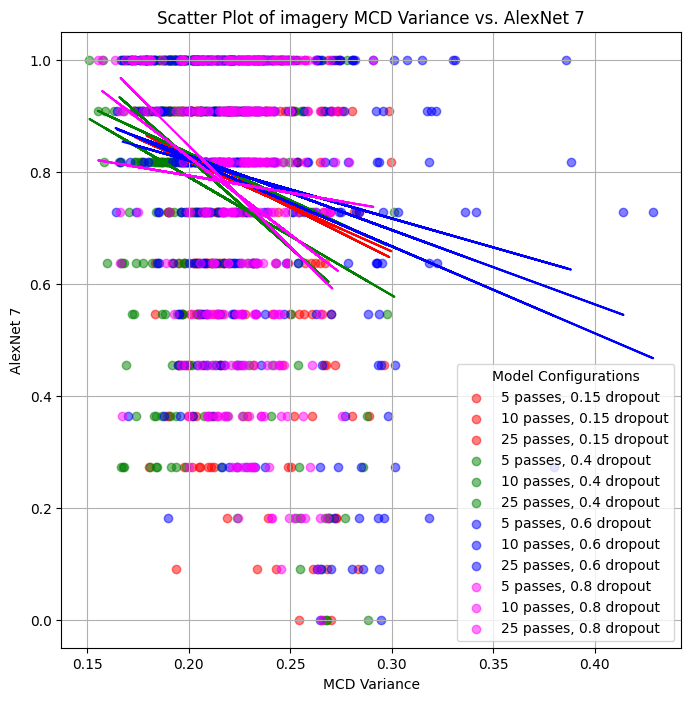

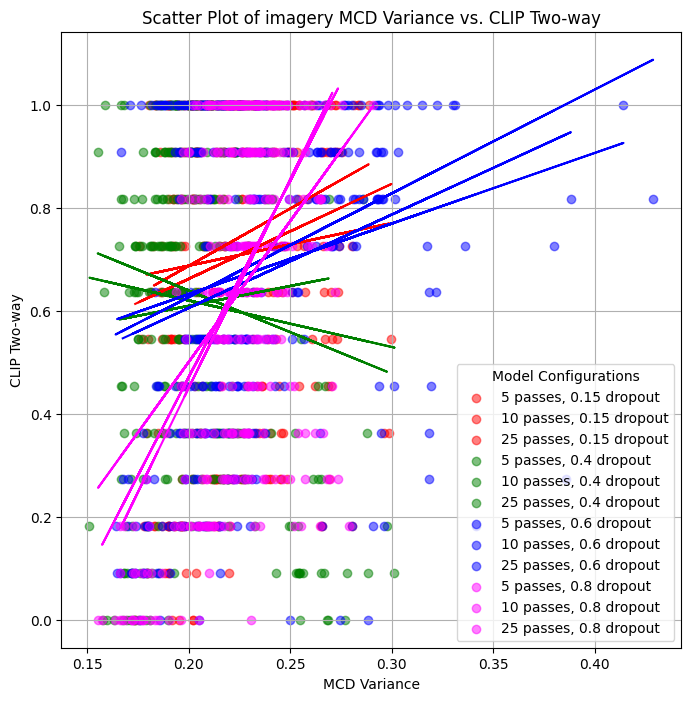

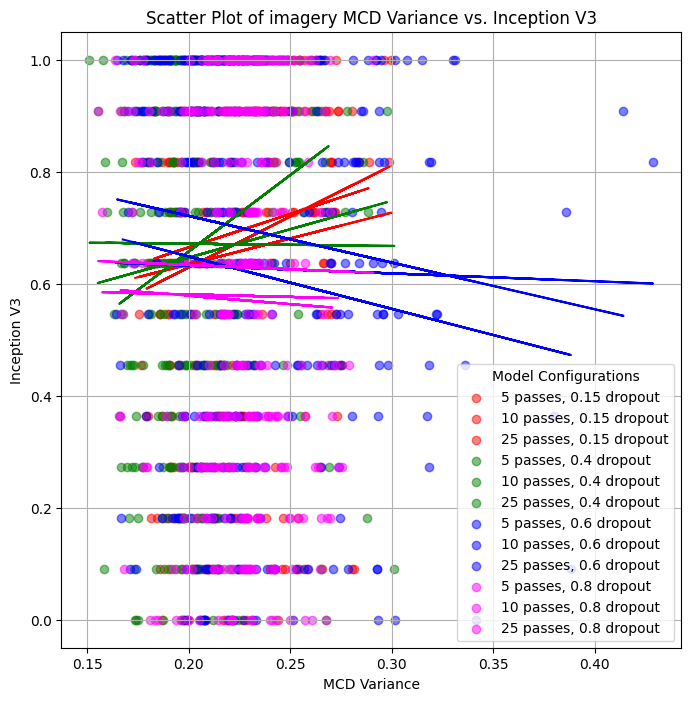

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Setting up the data
dropout_rates = [0.15, 0.4, 0.6, 0.8]
passes = [5, 10, 25]
mode = "imagery"
metrics = ["CLIP Cosine", "Brain Correlation NSD General", "Brain Correlation Early Visual", "SSIM", "Pixel Correlation", "EffNet-B", "SwAV", "AlexNet 7", "CLIP Two-way", "Inception V3"]
colors = ['red', 'green', 'blue', 'magenta']  # One color per dropout rate

# Create a plot for each metric
for metric in metrics:
    plt.figure(figsize=(8, 8))

    # Loop through each combination of dropout rate and passes
    for i, dropout_rate in enumerate(dropout_rates):
        for pass_count in passes:
            model = f"mindeye_mcd_{pass_count}passes_{dropout_rate}dr"
            file_path = f"../output/mental_imagery_paper_b3/{mode}/{model}/subject1_statistics_18.csv"
            df = pd.read_csv(file_path)
            df = df[(df['Sample Indicator'] == 12) & (df['ID'] < 12)]
            if 'MCD Var' in df and metric in df:
                x = df['MCD Var'].dropna()
                y = df[metric][x.index]
                
                # Skip plotting if there's insufficient data
                if x.empty or y.dropna().empty:
                    continue
                
                # Calculating the line of best fit
                slope, intercept = np.polyfit(x, y, 1)
                line_of_best_fit = slope * x + intercept

                # Plotting the data
                plt.scatter(x, y, alpha=0.5, color=colors[i], label=f'{pass_count} passes, {dropout_rate} dropout')
                plt.plot(x, line_of_best_fit, color=colors[i])  # Line of best fit in the same color

    plt.title(f'Scatter Plot of {mode} MCD Variance vs. {metric}')
    plt.xlabel('MCD Variance')
    plt.ylabel(metric)
    plt.grid(True)
    plt.legend(title='Model Configurations')
    plt.show()


In [ ]:
from scipy.stats import pearsonr
import numpy as np
# NSD SHARED1000 STATS
model = "mindeye_mcd_25passes_0.4dr_projector"
mode = "vision"
print(f"Current Model: {model} in mode: {mode}")
df = pd.read_csv(f"output/dataframes/{model}/subject1/subject1_statistics_1000.csv")
# df = pd.read_csv(f"../output/mental_imagery_paper_b3/{mode}/{model}/subject1_statistics_18.csv")
df = df[(df['Sample Indicator'] == 12)]# & (df['ID'] < 12)]
# print(df)
# df = df.replace([np.inf, -np.inf], np.nan)
non_image_metrics = ["CLIP Cosine", "Brain Correlation NSD General", "Brain Correlation Early Visual"]

for metric in non_image_metrics:
    filtered_df = df.dropna(subset=[metric]).replace([np.inf, -np.inf], np.nan)
    correlation, _ = pearsonr(filtered_df[metric], filtered_df['MCD Var'])
    print(f"{metric} Correlation-MCD Var Correlation: {correlation:.4f}")
    
df = df[(df['Sample Indicator'] == 12) & (df['ID'] < 12)]

image_metrics = ["SSIM", "Pixel Correlation", "AlexNet 2", "AlexNet 5", "AlexNet 7", "CLIP Two-way", "Inception V3"]
for metric in image_metrics:
    filtered_df = df.dropna(subset=[metric]).replace([np.inf, -np.inf], np.nan)
    correlation, _ = pearsonr(filtered_df[metric], filtered_df['MCD Var'])
    print(f"{metric}-MCD Var Correlation: {correlation:.4f}")

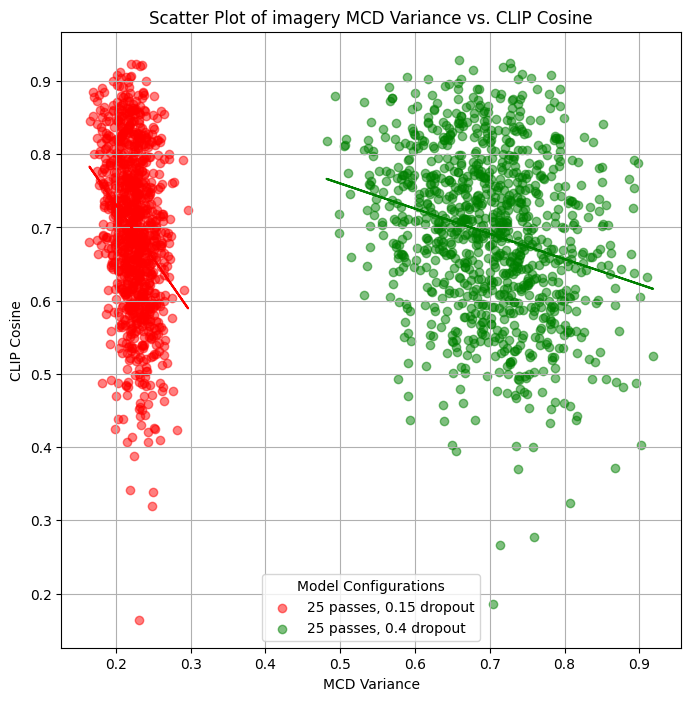

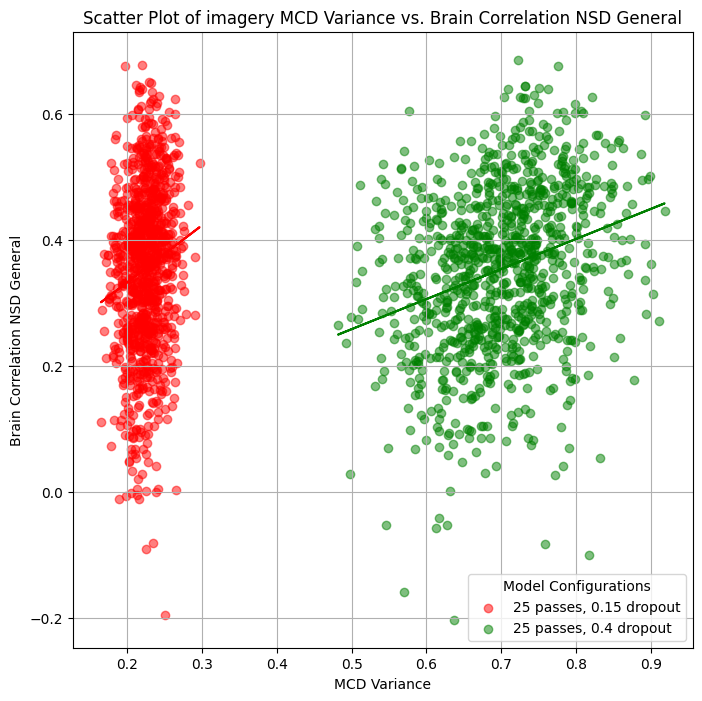

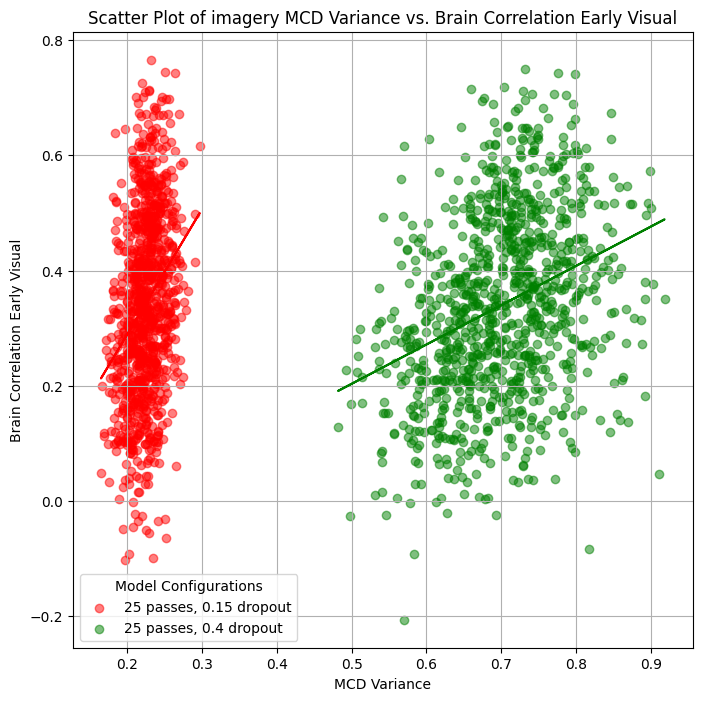

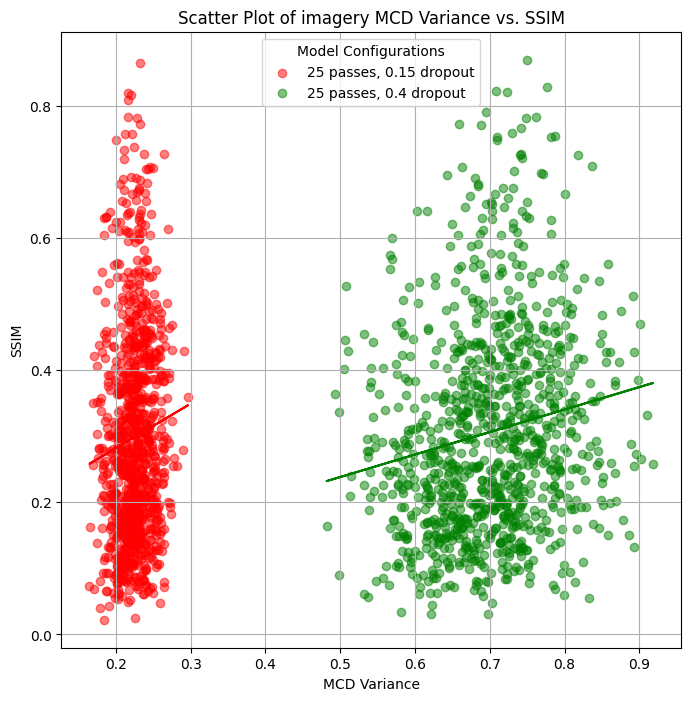

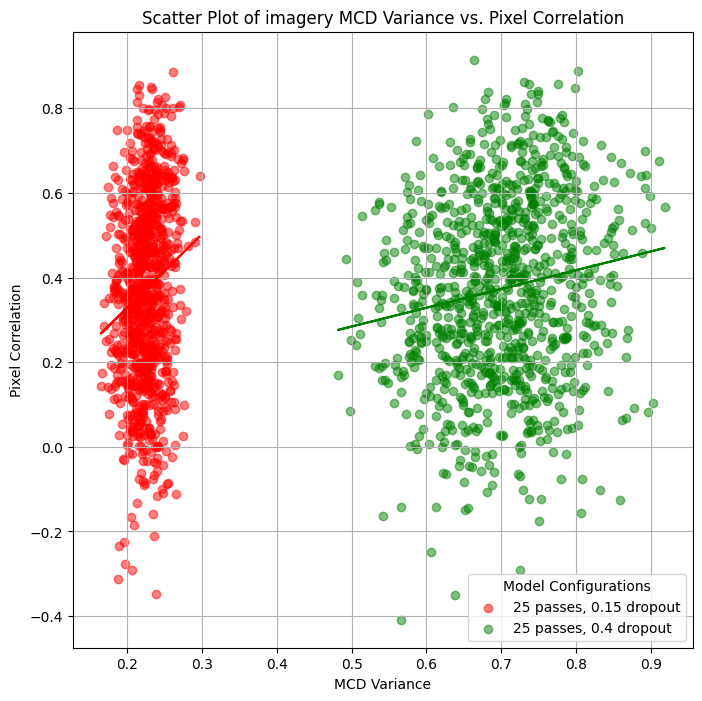

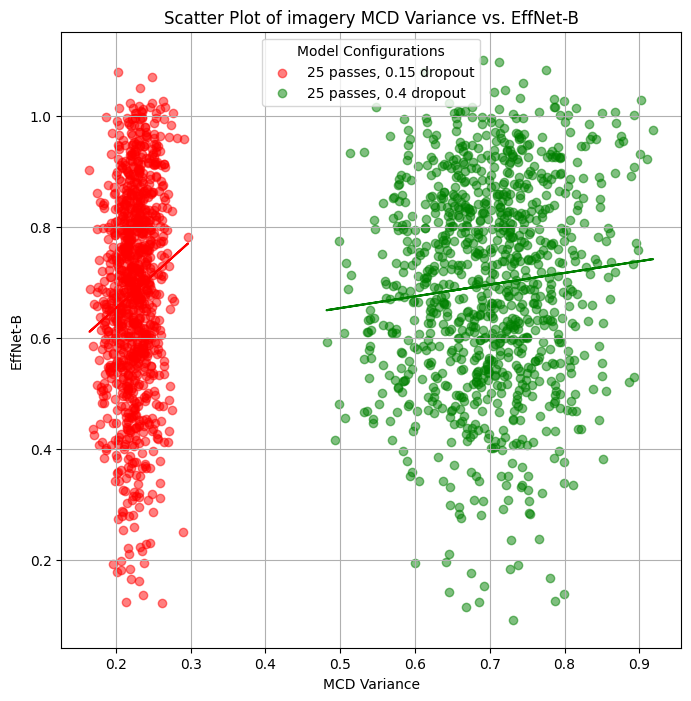

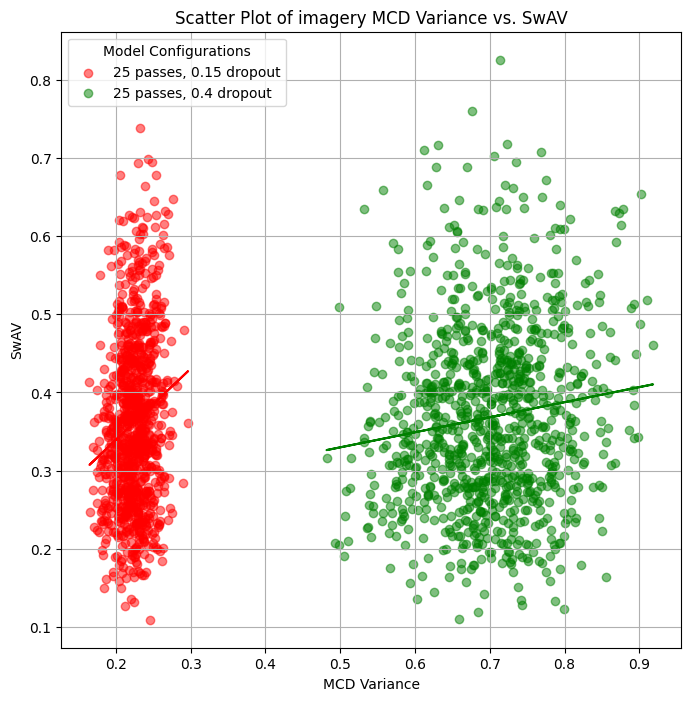

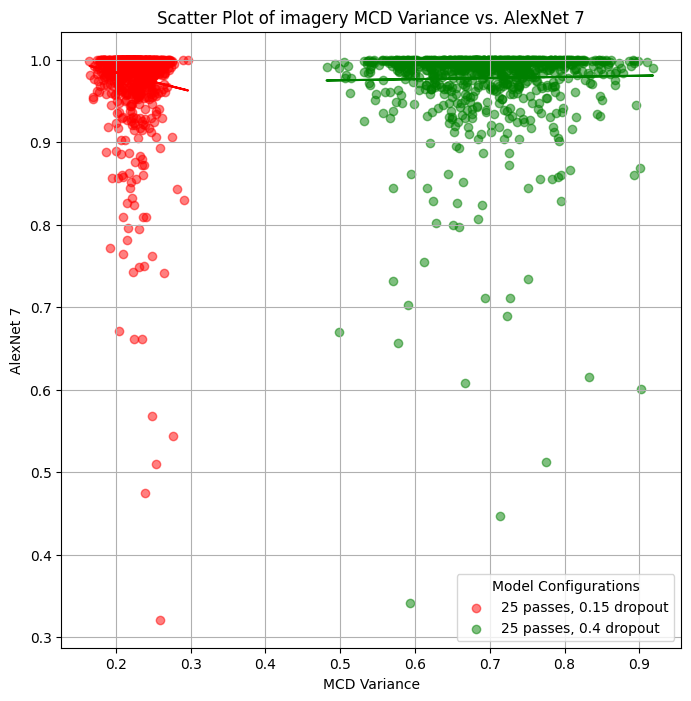

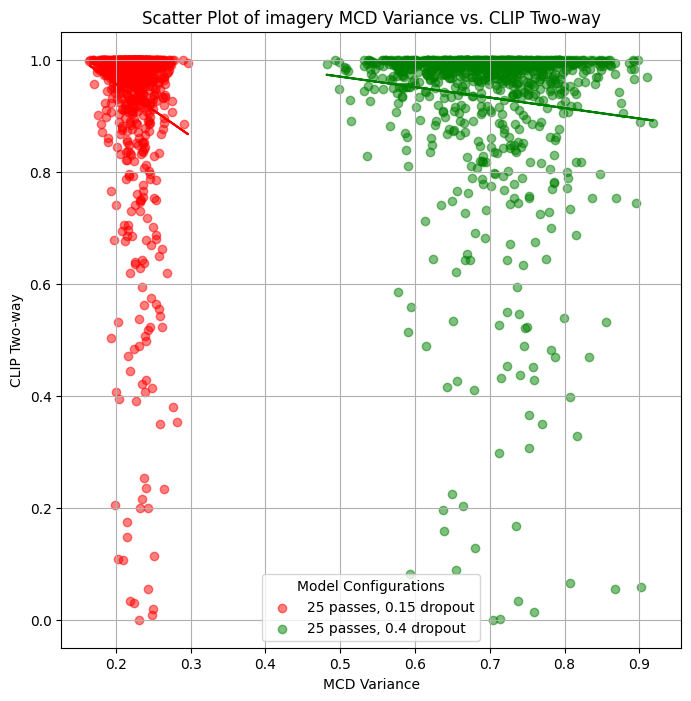

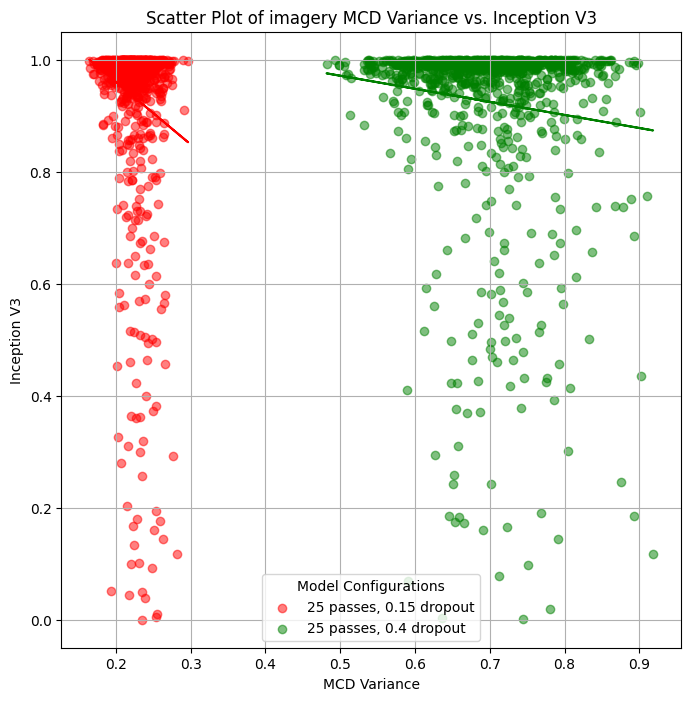

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
#SHARED1000 PLOTS
# Setting up the data
dropout_rates = [0.15, 0.4] #0.6, 0.8
passes = [25]
mode = "imagery"
metrics = ["CLIP Cosine", "Brain Correlation NSD General", "Brain Correlation Early Visual", "SSIM", "Pixel Correlation", "EffNet-B", "SwAV", "AlexNet 7", "CLIP Two-way", "Inception V3"]
colors = ['red', 'green', 'blue', 'magenta']  # One color per dropout rate

# Create a plot for each metric
for metric in metrics:
    plt.figure(figsize=(8, 8))

    # Loop through each combination of dropout rate and passes
    for i, dropout_rate in enumerate(dropout_rates):
        for pass_count in passes:
            model = f"mindeye_mcd_{pass_count}passes_{dropout_rate}dr_projector"
            file_path = f"output/dataframes/{model}/subject1/subject1_statistics_1000.csv"
            df = pd.read_csv(file_path)
            df = df[(df['Sample Indicator'] == 12)]
            if 'MCD Var' in df and metric in df:
                x = df['MCD Var'].dropna()
                y = df[metric][x.index]
                
                # Skip plotting if there's insufficient data
                if x.empty or y.dropna().empty:
                    continue
                
                # Calculating the line of best fit
                slope, intercept = np.polyfit(x, y, 1)
                line_of_best_fit = slope * x + intercept

                # Plotting the data
                plt.scatter(x, y, alpha=0.5, color=colors[i], label=f'{pass_count} passes, {dropout_rate} dropout')
                plt.plot(x, line_of_best_fit, color=colors[i])  # Line of best fit in the same color

    plt.title(f'Scatter Plot of {mode} MCD Variance vs. {metric}')
    plt.xlabel('MCD Variance')
    plt.ylabel(metric)
    plt.grid(True)
    plt.legend(title='Model Configurations')
    plt.show()


In [19]:
reducer = umap.UMAP(random_state=42)
plt.figure(figsize=(5, 5))
# Define a colormap with 18 distinct colors
cmap = colors.get_named_colors_mapping()
color_list = list(cmap.keys())
print(color_list_imagery)

sample_id = 0
# data_block = torch.vstack([clip_block_imagery[sample_id].reshape((reps*passes, embed_dim)), clip_block_vision[sample_id].reshape((reps*passes, embed_dim))]).numpy()
data_block = clip_block_imagery[sample_id].reshape((reps*passes, embed_dim)).numpy()
print(data_block.shape)
embedding_block = reducer.fit_transform(data_block)
split_len = int(len(data_block)/2)


NameError: name 'color_list_imagery' is not defined

<Figure size 500x500 with 0 Axes>

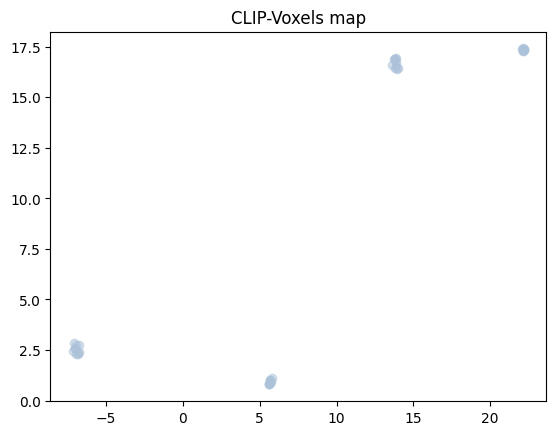

In [47]:

# imagery_embeddings = embedding_block[:split_len].reshape(reps,passes,2)
# vision_embeddings = embedding_block[split_len:].reshape(reps,passes,2)

imagery_embeddings = embedding_block.reshape(reps,passes,2)

# for i in range(reps):
i=0
plt.scatter(imagery_embeddings[:,0:2,0], imagery_embeddings[:,0:2,1], c=color_list[i], label=range(passes), alpha=.5)
plt.scatter(vision_embeddings[:,0:2,0], vision_embeddings[:,0:2,1], c=color_list[i], label=range(passes), alpha=.5)

# plt.scatter(embedding[:split_len, 0], embedding[:split_len, 1], c='blue', label='Images', alpha=.5)
# plt.scatter(embedding[split_len:, 0], embedding[split_len:, 1], c=color, label=label, alpha=.5)
plt.title(f'CLIP-Voxels map')
plt.savefig(f"../output/mental_imagery_paper_b3/figures/{model_name}_umap_clip.png")
plt.show()

In [10]:
reducer = umap.UMAP(random_state=42)
plt.figure(figsize=(5, 5))
# Define a colormap with 18 distinct colors
# cmap = colors.get_named_colors_mapping()
# color_list = list(cmap.keys())

sample_id = 0

x_train, _, x_test, _, _, _, _ = load_nsd(vector="images", subject=1, loader=False, average=True, nest=False, include_heldout=True, split_val=False)

x_test_mi_vision, _ = load_nsd_mental_imagery(subject=1, mode="vision", stimtype="all", average=True, nest=False)

x_test_mi_imagery, _ = load_nsd_mental_imagery(subject=1, mode="imagery", stimtype="all", average=True, nest=False)

print(x_train.shape, x_test.shape, x_test_mi_vision.shape, x_test_mi_imagery.shape)



torch.Size([30000, 15724])


loading samples: 100%|██████████| 30000/30000 [00:11<00:00, 2695.10it/s] 


Data Shapes... x_train: torch.Size([27000, 15724]), x_val: torch.Size([0]), x_test: torch.Size([1000, 15724]), y_train: torch.Size([27000, 541875]), y_val: torch.Size([0]), y_test: torch.Size([1000, 541875])
torch.Size([18, 1, 15724]) torch.Size([18, 3, 425, 425])
torch.Size([18, 1, 15724]) torch.Size([18, 3, 425, 425])
torch.Size([27000, 15724]) torch.Size([1000, 15724]) torch.Size([18, 1, 15724]) torch.Size([18, 1, 15724])


<Figure size 500x500 with 0 Axes>

torch.Size([1036, 15724])


/export/raid1/home/kneel027/miniconda3/envs/SS/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


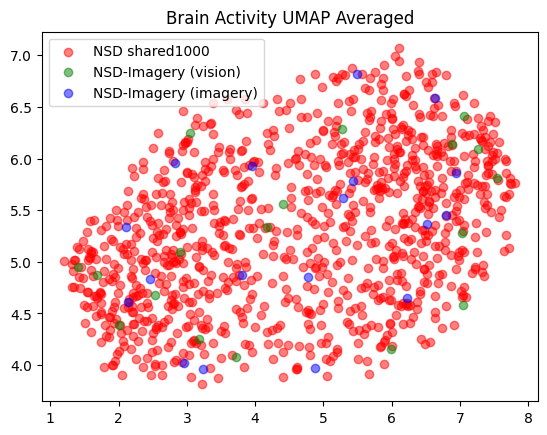

In [12]:
data_block = torch.concat([x_test, x_test_mi_vision[:,0,:], x_test_mi_imagery[:,0,:]]) #x_train, 
print(data_block.shape)
color_list = ['red', 'green', 'blue', 'orange']
embedding_block = reducer.fit_transform(data_block)
# split_lens = [0, x_train.shape[0], x_test.shape[0] + x_train.shape[0], x_test_mi_vision.shape[0] + x_train.shape[0] + x_test.shape[0], x_test_mi_imagery.shape[0] + x_train.shape[0] + x_test.shape[0] + x_test_mi_vision.shape[0]]
split_lens = [0, x_test.shape[0], x_test_mi_vision.shape[0] + x_test.shape[0], x_test_mi_imagery.shape[0] + x_test_mi_vision.shape[0] + x_test.shape[0]]
# captions = ["NSD Train", "NSD shared1000", "NSD-Imagery (vision)", "NSD-Imagery (imagery)"]
captions = ["NSD shared1000", "NSD-Imagery (vision)", "NSD-Imagery (imagery)"]

for i in range(3):
    plt.scatter(embedding_block[split_lens[i]:split_lens[i+1],0], embedding_block[split_lens[i]:split_lens[i+1],1], c=color_list[i], label=captions[i], alpha=.5)

# plt.scatter(embedding[:split_len, 0], embedding[:split_len, 1], c='blue', label='Images', alpha=.5)
# plt.scatter(embedding[split_len:, 0], embedding[split_len:, 1], c=color, label=label, alpha=.5)
plt.title(f'Brain Activity UMAP Averaged')
plt.legend()
plt.savefig(f"output/mental_imagery_paper_b3/figures/brain_activity_umap_averaged.png")
plt.show()

In [22]:
from scipy.stats import pearsonr
import numpy as np
model = "mindeye_mcd_25passes_0.15dr"
mode = "imagery"
print(f"Current Model: {model} in mode: {mode}")
df = pd.read_csv(f"output/mental_imagery_paper_b3/{mode}/{model}/subject1_statistics_18.csv")
filtered_df = df[(df['Sample Indicator'] == 12) & (df['ID'] < 6)]
average_mcd_var = filtered_df['MCD Var'].mean()
print("Average MCD Var for simple stimuli:", average_mcd_var)

filtered_df = df[(df['Sample Indicator'] == 12) & (df['ID'] >= 6) & (df['ID'] < 12)]
average_mcd_var = filtered_df['MCD Var'].mean()
print("Average MCD Var for complex stimuli:", average_mcd_var)

filtered_df = df[(df['Sample Indicator'] == 12) & (df['ID'] >= 12)]
average_mcd_var = filtered_df['MCD Var'].mean()
print("Average MCD Var for conceptual stimuli:", average_mcd_var)


Current Model: mindeye_mcd_25passes_0.15dr in mode: imagery
Average MCD Var for simple stimuli: 0.21781941627462706
Average MCD Var for complex stimuli: 0.22571102951963742
Average MCD Var for conceptual stimuli: 0.24694052239259084
